# Training on a device mesh with expex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davidesartor/expex/blob/main/examples/notebooks/multidevice.ipynb)

> **Python 3.14+ is needed.** expex requires Python 3.14, and Colab's hosted runtimes ship
> Python 3.12 (the 2026.01 runtime has 3.12.12), so on a hosted runtime the setup cell stops
> with a message. To run this notebook in Colab, start Jupyter on Python 3.14 on your machine
> and use *Connect → Connect to a local runtime*
> ([how](https://github.com/davidesartor/expex/blob/main/examples/notebooks/README.md#running-in-colab)),
> or open it in Jupyter directly. If *Runtime → Change runtime type* offers a runtime with
> Python 3.14, that works too. The outputs below are from a run on a CPU.

The transformer of [`examples/transformer.py`](../transformer.py), trained on a 4 x 2 mesh of
devices (data x model), as in [`examples/multidevice/train.py`](../multidevice/train.py).
Every sharding comes from two axis names, `B="data"` and `D="model"`: the batch is split four
ways, the model width two ways, and the optimizer state (an optax AdamW state whose moments
are models) follows the parameters. No `PartitionSpec` is written anywhere.

On a CPU, JAX can simulate 8 devices. The device count is fixed when JAX starts, so the first
cell sets it, before anything imports JAX. (On a fresh Colab runtime, run it first.)

In [1]:
import os

os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=8"  # 8 simulated CPU devices

In [2]:
# Setup: install expex from GitHub (or use a local checkout) and fetch the examples.
EXPEX_REF = "main"  # the branch or tag of github.com/davidesartor/expex to install

import os, pathlib, subprocess, sys

if sys.version_info < (3, 14):
    raise RuntimeError(
        f"expex needs Python 3.14+, and this runtime has Python {sys.version.split()[0]}: "
        "connect to a local runtime with Python 3.14 (see the note at the top of the notebook)"
    )


def find_checkout() -> pathlib.Path | None:
    """A local checkout of expex: $EXPEX_REPO, or a folder above the working directory."""
    if os.environ.get("EXPEX_REPO"):
        return pathlib.Path(os.environ["EXPEX_REPO"]).resolve()
    for folder in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (folder / "src" / "expex").is_dir() and (folder / "examples").is_dir():
            return folder
    return None


def run(*cmd: str) -> None:
    subprocess.run(cmd, check=True)


REPO = find_checkout()
if REPO is None:  # Colab, or a notebook opened on its own: install from GitHub
    REPO = pathlib.Path("expex").resolve()
    run(sys.executable, "-m", "pip", "install", "-q", f"git+https://github.com/davidesartor/expex@{EXPEX_REF}", "optax")
    if not REPO.exists():  # the examples and the reference outputs of the originals
        run("git", "clone", "-q", "--depth", "1", "--branch", EXPEX_REF, "https://github.com/davidesartor/expex", str(REPO))
else:
    try:
        import expex  # noqa: F401
    except ImportError:
        run(sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO), "optax")
sys.path.insert(0, str(REPO / "examples" / "multidevice"))
print("Python", sys.version.split()[0], "| examples from", REPO.name)

Python 3.14.6 | examples from vigilant-barnacle


In [3]:
import inspect
import json
import subprocess
import sys
import time

import jax
import jax.numpy as jnp
import numpy as np

import expex

sys.argv = ["train.py", "--devices", "8"]  # train.py reads its options when it is imported
import train  # examples/multidevice/train.py
from transformer import Transformer  # examples/transformer.py

print(jax.device_count(), "devices:", jax.devices()[0].platform)
print(inspect.getsource(train.train_step))
print(inspect.getsource(Transformer))

8 devices: cpu
@expex.fn
def train_step[B, T](model: Transformer, opt_state, tokens: Int[B, T]) -> tuple[Transformer, Any, f32]:
    # loss is written for one sequence: called on B of them, it maps over the rows
    loss, grads = jax.value_and_grad(lambda m: m.loss(tokens).mean())(model)
    updates, opt_state = OPT.update(grads, opt_state, model)
    return optax.apply_updates(model, updates), opt_state, loss

@expex.struct
class Transformer[D, F]:
    embed: f32[Vocab, D] = dense
    blocks: list[Block[D, F]]
    norm: LayerNorm[D]
    unembed: f32[D, Vocab] = dense

    def __call__[T](self, tokens: Int[T]) -> f32[T, Vocab]:
        x = self.embed[tokens]
        for block in self.blocks:  # identical blocks: one lax.scan
            x = block(x)
        return self.norm(x) @ self.unembed

    def loss[T](self, tokens: Int[T]) -> f32:
        assert T >= 2
        logp = jax.nn.log_softmax(self(tokens[:-1]))
        return -jnp.take_along_axis(logp, tokens[1:, None], axis=1).mean()


## The annotated signatures

The model's methods and the training step, as expex reads them. The names `B` and `D` in
these annotations are what `expex.shard` maps to mesh axes.

In [4]:
import transformer


def signature(f):
    owner = f.name.rpartition(".")[0]
    return f"{owner}.{f.signature}" if owner else f.signature


for report in expex.prove(transformer):
    print(signature(report.fn))
for f in (train.train_step, train.hidden, train.logits):
    print(signature(f))

LayerNorm.__call__(self: LayerNorm, x: f32[D]) -> f32[D]
Attention.split[T](self: Attention, x: f32[T, D]) -> f32[heads, T, D // heads]
Attention.causal[T, K](q: f32[T, K], k: f32[T, K], v: f32[T, K]) -> f32[T, K]
Attention.__call__[T, H, K](self: Attention, x: f32[T, D]) -> f32[T, D]
MLP.__call__(self: MLP, x: f32[D]) -> f32[D]
Block.__call__[T](self: Block, x: f32[T, D]) -> f32[T, D]
Transformer.__call__[T](self: Transformer, tokens: Int[T]) -> f32[T, Vocab]
Transformer.loss[T](self: Transformer, tokens: Int[T]) -> f32[()]
train_step[B, T](model: Transformer, opt_state, tokens: Int[B, T]) -> tuple[Transformer, Any, f32[()]]
hidden[B, T, D](model: Transformer, tokens: Int[B, T]) -> f32[B, T, D]
logits[B, T](model: Transformer, tokens: Int[B, T]) -> f32[B, T, Vocab]


## Shardings from the annotations

`expex.device_put(state, mesh, B="data", D="model")` places every array by the names in its
annotation: a `f32[Vocab, D]` embedding is split by columns over `"model"`, a batch `Int[B, T]`
by rows over `"data"`, and everything else is replicated.

In [5]:
mesh = train.make_mesh(8)
print(f"mesh: {dict(mesh.shape)}, names: {train.NAMES}")
state = expex.device_put(train.init(), mesh, **train.NAMES)
model = state["model"]
tokens = expex.device_put(train.batch(0), mesh, annotation=train.TOKENS, **train.NAMES)
hidden = expex.shard(train.hidden, mesh, **train.NAMES)(model, tokens)
adam = state["opt"][1][0]  # chain(clip, adamw): adamw's state

print(f"\n{'array':<28} {'shape':<14} {'per device':<14} spec")
for name, x in [("embed  f32[Vocab, D]", model.embed), ("blocks[0].mlp.w1  f32[D, F]", model.blocks[0].mlp.w1),
                ("norm.scale  f32[D]", model.norm.scale), ("adam mu.blocks[0].attn.wq", adam.mu.blocks[0].attn.wq),
                ("tokens  Int[B, T]", tokens), ("hidden  f32[B, T, D]", hidden)]:  # fmt: skip
    print(f"{name:<28} {str(x.shape):<14} {str(train.per_device(x)):<14} {x.sharding.spec}")

mesh: {'data': 4, 'model': 2}, names: {'B': 'data', 'D': 'model'}



array                        shape          per device     spec
embed  f32[Vocab, D]         (128, 64)      (128, 32)      P(None, 'model')
blocks[0].mlp.w1  f32[D, F]  (64, 256)      (32, 256)      P('model',)
norm.scale  f32[D]           (64,)          (32,)          P('model',)
adam mu.blocks[0].attn.wq    (64, 64)       (32, 64)       P('model',)
tokens  Int[B, T]            (32, 33)       (8, 33)        P('data',)
hidden  f32[B, T, D]         (32, 33, 64)   (8, 33, 32)    P('data', None, 'model')


## Run it

10 steps of character-level training on the repository's LICENSE, with a jitted, sharded step
(`expex.shard(train_step, mesh, donate="auto", B="data", D="model")`) that reuses the model's
and optimizer's buffers:

In [6]:
del model, adam  # no other references: the step can reuse (donate) the buffers
losses, times, donated, state = train.train(state, mesh, 0, 10)
for i, loss in enumerate(losses):
    print(f"step {i}: loss {loss:.4f}")
print(f"{donated}/10 steps reused their inputs' buffers; {train.check_shardings(state, mesh)} arrays are where expex.shardings says")
model = state["model"]

step 0: loss 5.3112
step 1: loss 5.3532
step 2: loss 5.0260
step 3: loss 4.5511
step 4: loss 4.0514
step 5: loss 3.9514
step 6: loss 3.6398
step 7: loss 3.4881
step 8: loss 3.3146
step 9: loss 3.2641
10/10 steps reused their inputs' buffers; 74 arrays are where expex.shardings says


## What the annotations give

**Proofs** for every size, a **summary**, and the **cost** of the loss: they read the
annotations, not the shardings, so they count the whole model.

In [7]:
expex.prove(transformer)

ok    transformer.LayerNorm.__call__
ok    transformer.Attention.split
ok    transformer.Attention.causal
ok    transformer.Attention.__call__
ok    transformer.MLP.__call__
ok    transformer.Block.__call__
ok    transformer.Transformer.__call__
ok    transformer.Transformer.loss

8 functions: 8 proved

In [8]:
expex.summary(model, T=train.SEQ)

Transformer   (T=32, D=64, F=256, Vocab=128, L=2)
module     class                     params  formula                                       bytes   flops  flops formula
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
embed      f32[Vocab, D]              8,192  D·Vocab                                     32.8 kB
blocks[*]  Block[D=64, F=256]  × 2   49,408  4·D² + 2·D·F + 4·D                           198 kB  3.55 M  8·T·D² + 4·T²·D + 4·T·D·F + 31·T² + 20·T·D + 8·T·F + 16·T + 5
  norm1    LayerNorm[D=64]              128  2·D                                           512 B     584  9·D + 8
    scale  f32[D]                        64  D                                             256 B
    bias   f32[D]                        64  D                                             256 B
  attn     Attention[D=64]           16,384  4·D²                                        65.5 kB  1.34 M  8·T·D² + 4·T²·D + 31·T² + 4·T +

In [9]:
print(expex.cost(Transformer.loss, train.CONFIG, T=train.SEQ + 1))

Transformer.loss   (sizes: Vocab=128, D=64, F=256, L=2, T=33)
  flops        7656942   = 7.66 MFLOP
  parameters   115328   = 115 k
  largest      f32[4,T - 1,T - 1] (4096 elements)
  note: L = len(self.blocks)


**A diagram** of the model, drawn from the code (interactive when you run the notebook):

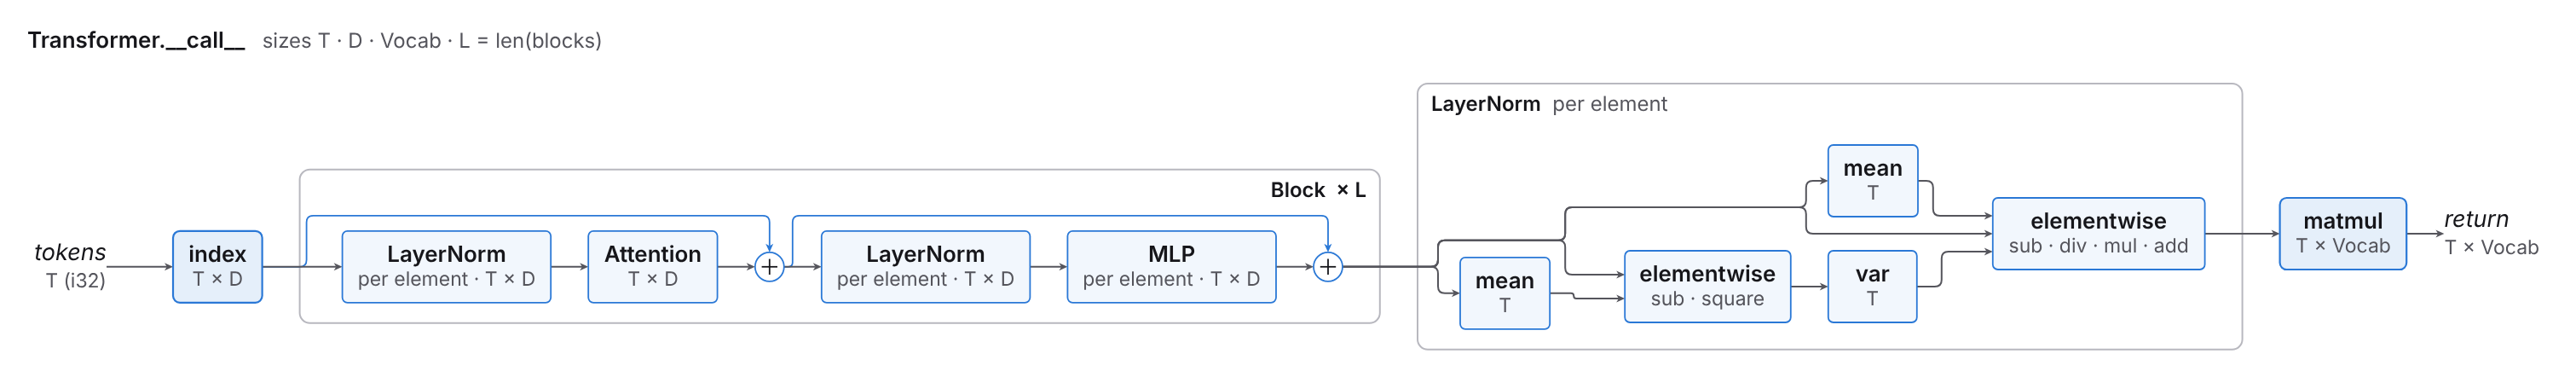

In [10]:
expex.diagram(Transformer.__call__, depth=2)

**`expex.inspect`**: every tool in one page, for the trained (sharded) model on one sequence:

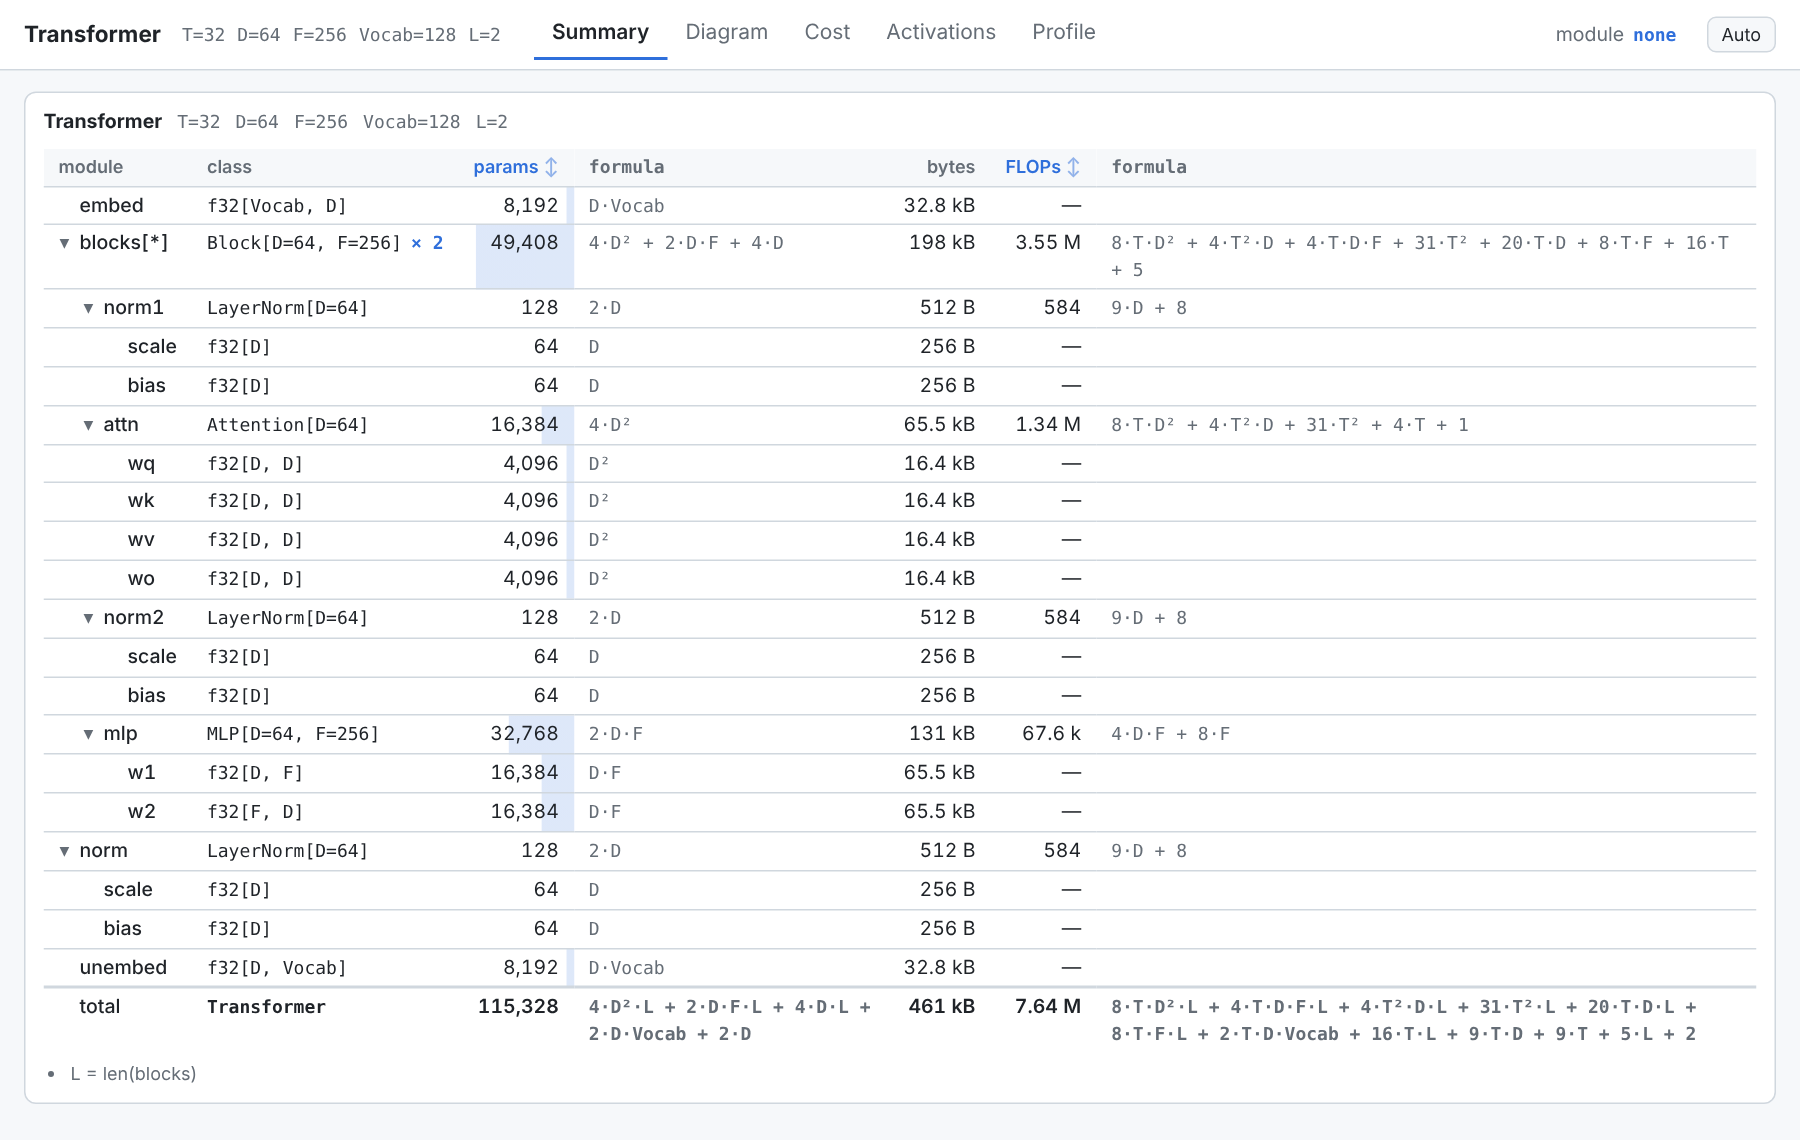

In [11]:
sequence = jnp.asarray(train.batch(1)[0])
expex.inspect(model, sequence[:-1], loss=lambda m, t: m.loss(sequence))

## A shape error

The sharded functions check their arguments like any typed call. Tokens as floats are refused:

In [12]:
try:
    expex.shard(train.logits, mesh, **train.NAMES)(model, tokens.astype(jnp.float32))
except expex.ShapeError as e:
    error = e
error

ShapeError: logits(): argument `tokens` does not match its annotation.

    declared  tokens: Int[B, T]
    received          f32[32, 33]

    expected dtype Int, got f32.

    logits[B, T](model: Transformer, tokens: Int[B, T]) -> f32[B, T, Vocab]
    defined at examples/multidevice/train.py:106
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex101


And placing a batch says when the mesh cannot split it: 30 sequences over the 4 devices of
`"data"`:

In [13]:
try:
    expex.device_put(train.batch(0)[:30], mesh, annotation=train.TOKENS, **train.NAMES)
except ValueError as e:
    print(e)

ArrayImpl: Int[B, T] has B = 30 on axis 0, which mesh axis 'data' cannot split evenly (4 devices do not divide 30).
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex602


## Activations and gradients, block by block

`expex.debug.watch` of the loss on one sequence, with the sharded model:

In [14]:
watch = expex.debug.watch(lambda m: m.loss(sequence), model)
print(f"{len(watch.rows)} calls, {len(watch.flagged)} flagged")
watch

21 calls, 0 flagged


watch <lambda>: loss 3.00828, 21 calls, 0 flagged  (grad_ratio=100.0, growth=10.0)
                                                      ────────────────output────────────────  ───────────────d loss / d output───────────────
  call                            shape           ×n      mean    std  |max|    rms  nan/inf       mean       std    |max|       rms  nan/inf  flags
  Transformer.loss                f32              1      3.01      0   3.01   3.01                   1         0        1         1
    Transformer.__call__          f32[32, 128]     1    -0.195   1.28      5   1.29           -3.64e-12   0.00263   0.0312   0.00263
      blocks[0].__call__          f32[32, 64]      1   -0.0218   1.48   4.32   1.48               4e-11    0.0014  0.00544    0.0014
        blocks[0].norm1.__call__  f32[64]         32  2.15e-06      1   3.97      1             1.1e-05   0.00172    0.011   0.00172
        blocks[0].attn.__call__   f32[32, 64]      1   0.00628  0.671    2.9  0.671           

## Against one device

There is no original to compare with here; the check is that sharding changes nothing. The same
10 steps on 1 device, in a new process (the device count is fixed per process):

In [15]:
script = REPO / "examples" / "multidevice" / "train.py"
env = {k: v for k, v in os.environ.items() if k != "XLA_FLAGS"}
out = subprocess.run([sys.executable, str(script), "--devices", "1", "--steps", "10", "--json"],
                     capture_output=True, text=True, check=True, env=env)  # fmt: skip
single = json.loads(out.stdout.strip().splitlines()[-1])
gap = max(abs(a - b) / abs(b) for a, b in zip(losses, single["losses"]))
print(f"{'step':>4}  {'8 devices':>10}  {'1 device':>10}")
for i, (a, b) in enumerate(zip(losses, single["losses"])):
    print(f"{i:>4}  {a:>10.6f}  {b:>10.6f}")
print(f"largest relative difference: {gap:.1e}")

step   8 devices    1 device
   0    5.311178    5.311178
   1    5.353208    5.353208
   2    5.025974    5.025974
   3    4.551115    4.551115
   4    4.051409    4.051410
   5    3.951378    3.951378
   6    3.639810    3.639810
   7    3.488083    3.488083
   8    3.314634    3.314634
   9    3.264118    3.264118
largest relative difference: 2.4e-07


## Speed

Median step time, compile excluded. The 8 simulated devices share this machine's cores, so they
are no speedup: the point is that it runs. Timings depend on the machine.

In [16]:
print(f"1 device:            {np.median(single['times'][1:]) * 1e3:6.1f} ms per step")
print(f"8 simulated devices: {np.median(times[1:]) * 1e3:6.1f} ms per step  ({os.cpu_count()} CPU cores)")

1 device:              21.5 ms per step
8 simulated devices:   24.3 ms per step  (4 CPU cores)
